In [ ]:
# Установка системных зависимостей OpenCL (для GPU-версии LightGBM)
!apt-get install -y opencl-headers ocl-icd-libopencl1 ocl-icd-opencl-dev

# Удаление стандартной версии LightGBM (без поддержки GPU)
!pip uninstall -y lightgbm

# Установка предварительно скомпилированной версии LightGBM с поддержкой GPU (адаптированной для Colab)
!pip install lightgbm --install-option=--gpu --install-option="--opencl-include-dir=/usr/include/" --install-option="--opencl-library=/usr/lib/x86_64-linux-gnu/libOpenCL.so.1"

>>> Загрузка данных...
Размер датасета: (284807, 31)
Распределение классов:
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64
Train size: (199364, 30), Test size: (85443, 30)

>>> Задание 1: Обучение базовых моделей...
Обучение Bagging...
Bagging Macro F1: 0.9190
Обучение Random Forest...
Random Forest Macro F1: 0.9077
Обучение базового LightGBM...
LightGBM Macro F1: 0.9159

>>> Задание 2: Оптимизация LightGBM (Optuna, 30 trials)...


  0%|          | 0/30 [00:00<?, ?it/s]

Лучшие параметры LightGBM: {'learning_rate': 0.1914054573469132, 'num_leaves': 73, 'max_depth': 12, 'min_child_samples': 38, 'subsample': 0.9545191680346852, 'colsample_bytree': 0.9612601348273856}
Лучший Macro F1 LightGBM: 0.9258

>>> Задание 3: Оптимизация CatBoost (Optuna, 20 trials)...


  0%|          | 0/20 [00:00<?, ?it/s]

Лучшие параметры CatBoost: {'learning_rate': 0.18007668188998177, 'depth': 8, 'l2_leaf_reg': 1.0880167321348386, 'random_strength': 6.7530738790386575, 'subsample': 0.6178688801323912}
Лучший Macro F1 CatBoost: 0.9243
ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ
Bagging             : 0.9190
Random Forest       : 0.9077
LightGBM (base)     : 0.9159
LightGBM (tuned)    : 0.9258
CatBoost (tuned)    : 0.9243

Лучшая модель: LightGBM (tuned) с Macro F1 = 0.9258


<Figure size 600x500 with 0 Axes>

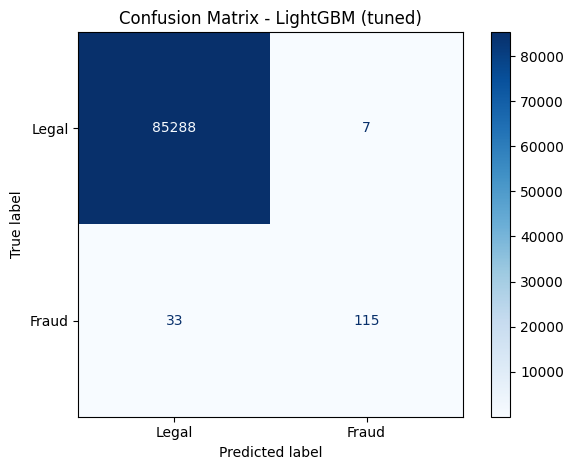


Classification Report (LightGBM (tuned)):
              precision    recall  f1-score   support

       Legal       1.00      1.00      1.00     85295
       Fraud       0.94      0.78      0.85       148

    accuracy                           1.00     85443
   macro avg       0.97      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443



In [8]:
# -*- coding: utf-8 -*-
"""
Полное решение задачи классификации мошеннических транзакций (Credit Card Fraud Detection).
Задания:
1. Бэггинг, случайный лес, LightGBM.
2. Оптимизация LightGBM (Optuna), матрица ошибок для лучшей модели.
3. Оптимизация CatBoost (Optuna).
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

import lightgbm as lgb
from catboost import CatBoostClassifier
import optuna

# Отключаем лишние предупреждения для чистоты вывода
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)


# Загрузка и подготовка данных
def load_and_split_data(filepath='creditcard.csv'):
    print(">>> Загрузка данных...")
    try:
        df = pd.read_csv(filepath)
    except FileNotFoundError:
        print(f"Ошибка: Файл {filepath} не найден. Убедитесь, что он находится в рабочей директории.")
        exit(1)

    print(f"Размер датасета: {df.shape}")
    print(f"Распределение классов:\n{df['Class'].value_counts(normalize=True)}")

    X = df.drop('Class', axis=1)
    y = df['Class']

    # Разделение на train/test (30% тест, стратификация)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, stratify=y, random_state=42
    )
    print(f"Train size: {X_train.shape}, Test size: {X_test.shape}")
    return X_train, X_test, y_train, y_test


# Базовые модели (Бэггинг, RF, LightGBM)
def train_baseline_models(X_train, X_test, y_train, y_test):
    print("\n>>> Задание 1: Обучение базовых моделей...")
    results = {}

    # Bagging
    print("Обучение Bagging...")
    bagging_clf = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    )
    bagging_clf.fit(X_train, y_train)
    y_pred_bagging = bagging_clf.predict(X_test)
    f1_bagging = f1_score(y_test, y_pred_bagging, average='macro')
    results['Bagging'] = f1_bagging
    print(f"Bagging Macro F1: {f1_bagging:.4f}")

    # Random Forest
    print("Обучение Random Forest...")
    rf_clf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    )
    rf_clf.fit(X_train, y_train)
    y_pred_rf = rf_clf.predict(X_test)
    f1_rf = f1_score(y_test, y_pred_rf, average='macro')
    results['Random Forest'] = f1_rf
    print(f"Random Forest Macro F1: {f1_rf:.4f}")

    # LightGBM (базовый)
    print("Обучение базового LightGBM...")
    lgb_clf = lgb.LGBMClassifier(
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    )
    lgb_clf.fit(X_train, y_train)
    y_pred_lgb = lgb_clf.predict(X_test)
    f1_lgb = f1_score(y_test, y_pred_lgb, average='macro')
    results['LightGBM (base)'] = f1_lgb
    print(f"LightGBM Macro F1: {f1_lgb:.4f}")

    return results, lgb_clf


# Оптимизация LightGBM
def optimize_lightgbm(X_train, X_test, y_train, y_test, n_trials=30):
    print(f"\n>>> Задание 2: Оптимизация LightGBM (Optuna, {n_trials} trials)...")

    def objective(trial):
        param = {
            'objective': 'binary',
            'metric': 'binary_logloss',
            'verbosity': -1,
            'boosting_type': 'gbdt',
            'random_state': 42,
            'n_jobs': -1,
            'class_weight': 'balanced',
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2),
            'num_leaves': trial.suggest_int('num_leaves', 20, 100),
            'max_depth': trial.suggest_int('max_depth', 3, 12),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        }
        model = lgb.LGBMClassifier(**param)
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        return f1_score(y_test, preds, average='macro')

    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

    print(f"Лучшие параметры LightGBM: {study.best_params}")
    print(f"Лучший Macro F1 LightGBM: {study.best_value:.4f}")

    # Обучение финальной модели с лучшими параметрами
    best_lgb = lgb.LGBMClassifier(
        **study.best_params,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    )
    best_lgb.fit(X_train, y_train)
    return best_lgb, study.best_value


# Оптимизация CatBoost
def optimize_catboost(X_train, X_test, y_train, y_test, n_trials=20):
    print(f"\n>>> Задание 3: Оптимизация CatBoost (Optuna, {n_trials} trials)...")

    def objective(trial):
        param = {
            'iterations': 500,
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2),
            'depth': trial.suggest_int('depth', 4, 10),
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10),
            'random_strength': trial.suggest_float('random_strength', 1e-3, 10),
            'bootstrap_type': 'Bernoulli',
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'auto_class_weights': 'Balanced',
            'verbose': False,
            'random_state': 42,
        }
        model = CatBoostClassifier(**param)
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        return f1_score(y_test, preds, average='macro')

    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

    print(f"Лучшие параметры CatBoost: {study.best_params}")
    print(f"Лучший Macro F1 CatBoost: {study.best_value:.4f}")

    # Обучение финальной модели
    best_cat = CatBoostClassifier(**study.best_params, verbose=False, random_state=42)
    best_cat.fit(X_train, y_train)
    return best_cat, study.best_value


# Построение матрицы ошибок и итоговый вывод
def plot_confusion_matrix_and_report(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legal', 'Fraud'])
    disp.plot(cmap=plt.cm.Blues, values_format='d')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.tight_layout()
    plt.savefig(f'confusion_matrix_{model_name.replace(" ", "_").lower()}.png')
    plt.show()

    print(f"\nClassification Report ({model_name}):")
    print(classification_report(y_test, y_pred, target_names=['Legal', 'Fraud']))

def main():
    # Загрузка
    X_train, X_test, y_train, y_test = load_and_split_data('creditcard.csv')

    # Базовые модели
    baseline_results, base_lgb = train_baseline_models(X_train, X_test, y_train, y_test)

    # LightGBM + Optuna
    best_lgb_model, best_lgb_f1 = optimize_lightgbm(X_train, X_test, y_train, y_test, n_trials=30)

    # CatBoost + Optuna
    best_cat_model, best_cat_f1 = optimize_catboost(X_train, X_test, y_train, y_test, n_trials=20)

    # Итоговое сравнение и выбор победителя
    print("ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ")
    for name, score in baseline_results.items():
        print(f"{name:20s}: {score:.4f}")
    print(f"{'LightGBM (tuned)':20s}: {best_lgb_f1:.4f}")
    print(f"{'CatBoost (tuned)':20s}: {best_cat_f1:.4f}")

    if best_cat_f1 > best_lgb_f1:
        best_model = best_cat_model
        best_name = "CatBoost (tuned)"
        best_score = best_cat_f1
    else:
        best_model = best_lgb_model
        best_name = "LightGBM (tuned)"
        best_score = best_lgb_f1

    print(f"\nЛучшая модель: {best_name} с Macro F1 = {best_score:.4f}")

    # Построение матрицы ошибок для лучшей модели
    plot_confusion_matrix_and_report(best_model, X_test, y_test, best_name)

if __name__ == "__main__":
    main()